Using the same features (but just their means) as the paper we can get a C-index of ~ 0.607. The model is correctly predicting injuries better than a random guess.


In [6]:
from lifelines import CoxPHFitter, KaplanMeierFitter
import pandas as pd
df = pd.read_csv('data/raw/day_approach_maskedID_timeseries.csv')
df = df.sort_values(['Athlete ID', 'Date']).reset_index(drop=True)

baseline_data = []

for athlete in df['Athlete ID'].unique():
    athlete_df = df[df['Athlete ID'] == athlete]
    
    # Time: number of days observed
    T = len(athlete_df)
    
    # Event: did injury occur
    E = int(athlete_df['injury'].sum() > 0)
    
    total_km_mean = athlete_df['total km'].mean()
    perceived_exertion_mean = athlete_df['perceived exertion'].mean()
    
    baseline_data.append({
        'athlete_id': athlete,
        'days_observed': T,
        'injured': E,
        'avg_total_km': total_km_mean,
        'avg_exertion': perceived_exertion_mean,
    })

baseline_df = pd.DataFrame(baseline_data)

cph = CoxPHFitter()
cph.fit(baseline_df[['avg_total_km', 'avg_exertion', 'days_observed', 'injured']], 
        duration_col='days_observed', event_col='injured')

print(cph.summary)
print(f"C-index: {cph.concordance_index_:.3f}")

FileNotFoundError: [Errno 2] No such file or directory: 'data/raw/day_approach_maskedID_timeseries.csv'

test XGBoost

In [3]:
from xgboost import XGBClassifier
# read data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(data['data'], data['target'], test_size=.2)
# create model instance
bst = XGBClassifier(n_estimators=2, max_depth=2, learning_rate=1, objective='binary:logistic')
# fit model
bst.fit(X_train, y_train)
# make predictions
preds = bst.predict(X_test)


[1 0 1 1 0 0 1 1 0 2 1 1 0 2 0 0 1 1 2 0 0 2 2 0 2 0 1 1 2 0]


For our imbalanced data we will use: https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedBaggingClassifier.html 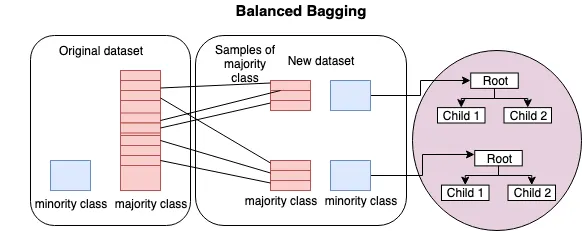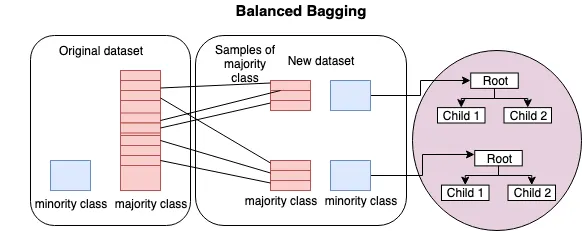

In [4]:
%pip install imbalanced-learn

/Users/hayden/Documents/InjuryPredictor/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [2]:

from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from imblearn.ensemble import BalancedBaggingClassifier
from numpy import mean

# Generate a synthetic imbalanced dataset
X, y = make_classification(n_samples=10000, n_features=2, weights=[0.99], random_state=4, n_redundant=0)

# Define the BalancedBaggingClassifier model
model = BalancedBaggingClassifier(n_estimators=10, random_state=42)

# Evaluate the model using ROC AUC via cross-validation
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
scores = cross_val_score(model, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)

print('Mean ROC AUC: %.3f' % mean(scores))


ModuleNotFoundError: No module named 'imblearn'

normalize the independent variables using the
z score transform for each athlete individually, based on the mean
and SD of the healthy events of that athlete.

In the day approach, a feature vector is constructed by
expressing the week before the injury or healthy event as a series of days described by ten features per day (ie, 70 features in total,
Table 1). We count the days starting from 0, so the day before the
event is seen as day 0, 2 days before the event as day 1 and 7 days
before the event is day 6 